# F1 Baseline Analysis: Driver Win %, Fastest Laps & Car Dependency

Reads from the local CSV data store generated by `ingest_f1.py` (`data/store/f1_master.csv`).

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)

df = pd.read_csv("data/store/f1_master.csv", parse_dates=["date"])
print(f"Loaded {len(df):,} driver-race rows | Seasons: {df['season'].min()}–{df['season'].max()}")
df.head(3)

Loaded 26,224 driver-race rows | Seasons: 1950–2026


,race_id,season,round,driver_id,constructor_id,grid,position,position_text,points,laps,...,date,circuit_id,country,driver_code,full_name,nationality,constructor_name,wcc_constructor_id,wcc_constructor_name,in_wcc_car
0,1950_01,1950,1,farina,alfa,1,1,1,9.0,70,...,1950-05-13,silverstone,UK,NaN,Nino Farina,Italian,Alfa Romeo,NaN,NaN,False
1,1950_01,1950,1,fagioli,alfa,2,2,2,6.0,70,...,1950-05-13,silverstone,UK,NaN,Luigi Fagioli,Italian,Alfa Romeo,NaN,NaN,False
2,1950_01,1950,1,reg_parnell,alfa,4,3,3,4.0,70,...,1950-05-13,silverstone,UK,NaN,Reg Parnell,British,Alfa Romeo,NaN,NaN,False


## 1. Driver Win Percentage (All-Time & Modern Era)

Excludes 1950–1960 Indy 500 rounds (non-F1 grid) and filters by minimum race starts so one-off winners don't skew the leaderboard.

In [3]:
MIN_STARTS = 20

# Exclude 1950-1960 Indianapolis 500 rounds for a clean F1 comparison
f1_only = df[~((df["season"].between(1950, 1960)) & (df["circuit_id"] == "indianapolis"))]

driver_stats = (
    f1_only.groupby(["driver_id", "full_name"])
    .agg(
        starts=("race_id", "count"),
        wins=("is_win", "sum"),
        podiums=("is_podium", "sum"),
        fastest_laps=("is_fastest_lap", "sum"),
        wcc_car_starts=("in_wcc_car", "sum"),
    )
    .reset_index()
    .assign(
        win_pct=lambda d: (d["wins"] / d["starts"] * 100).round(2),
        podium_pct=lambda d: (d["podiums"] / d["starts"] * 100).round(2),
        wcc_car_pct=lambda d: (d["wcc_car_starts"] / d["starts"] * 100).round(1),
    )
    .query("starts >= @MIN_STARTS")
    .sort_values("win_pct", ascending=False)
)

driver_stats.head(15)

,driver_id,full_name,starts,wins,podiums,fastest_laps,wcc_car_starts,win_pct,podium_pct,wcc_car_pct
203,fangio,Juan Fangio,51,24,35,0,0,47.06,68.63,0.0
30,ascari,Alberto Ascari,31,13,17,0,0,41.94,54.84,0.0
145,clark,Jim Clark,72,25,32,0,20,34.72,44.44,27.8
440,michael_schumacher,Michael Schumacher,308,91,155,21,112,29.55,50.32,36.4
426,max_verstappen,Max Verstappen,253,74,139,38,44,29.25,54.94,17.4
634,stewart,Jackie Stewart,100,27,43,0,22,27.00,43.00,22.0
280,hamilton,Lewis Hamilton,400,106,209,70,159,26.50,52.25,39.8
613,senna,Ayrton Senna,161,41,80,0,67,25.47,49.69,41.6
537,prost,Alain Prost,202,51,106,0,80,25.25,52.48,39.6
459,moss,Stirling Moss,67,16,24,0,16,23.88,35.82,23.9


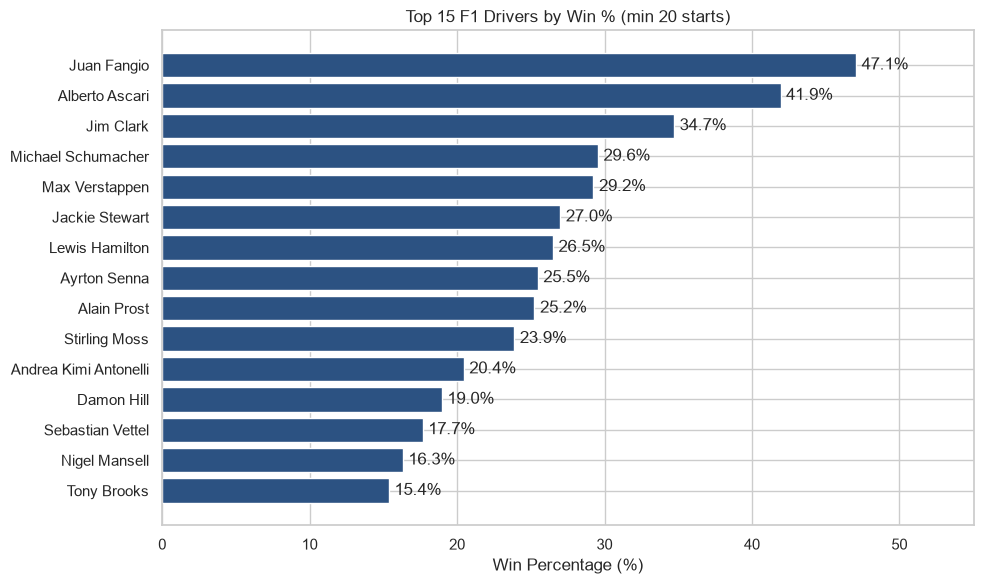

In [4]:
top15 = driver_stats.head(15).sort_values("win_pct")
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top15["full_name"], top15["win_pct"], color="#2c5282")
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set_title(f"Top 15 F1 Drivers by Win % (min {MIN_STARTS} starts)")
ax.set_xlabel("Win Percentage (%)")
ax.set_xlim(0, top15["win_pct"].max() + 8)
plt.tight_layout()
plt.show()

## 2. Fastest Lap in Every Race (2004–Present)

Official lap-time fastest lap rankings in Ergast/Jolpica are consistently populated from 2004 onward.

In [5]:
fastest_laps = (
    df[(df["season"] >= 2004) & (df["is_fastest_lap"])]
    [["season", "round", "race_name", "full_name", "constructor_name", "fastest_lap_time", "in_wcc_car"]]
    .sort_values(["season", "round"])
)

print(f"Total races with recorded fastest lap (2004–{df['season'].max()}): {len(fastest_laps):,}")
fastest_laps.tail(15)

Total races with recorded fastest lap (2004–2026): 455


,season,round,race_name,full_name,constructor_name,fastest_lap_time,in_wcc_car
25894,2026,6,Monaco Grand Prix,Andrea Kimi Antonelli,Mercedes,1:13.481,True
25916,2026,7,Barcelona Grand Prix,Lewis Hamilton,Ferrari,1:20.122,False
25940,2026,8,Austrian Grand Prix,Andrea Kimi Antonelli,Mercedes,1:10.374,True
25974,2026,9,British Grand Prix,Andrea Kimi Antonelli,Mercedes,1:31.777,True
25988,2026,10,Belgian Grand Prix,Lando Norris,McLaren,1:48.890,False
26007,2026,11,Hungarian Grand Prix,Charles Leclerc,Ferrari,1:22.000,False
26030,2026,12,Dutch Grand Prix,Charles Leclerc,Ferrari,1:14.230,False
26048,2026,13,Italian Grand Prix,Andrea Kimi Antonelli,Mercedes,1:23.504,True
26074,2026,14,Spanish Grand Prix,George Russell,Mercedes,1:35.587,True
26092,2026,15,Azerbaijan Grand Prix,George Russell,Mercedes,1:44.916,True


## 3. Car Dependency: How Much Depends on Driving the WCC Car?

Compares the share of **race wins** vs. **fastest laps** achieved by that season's Constructors' Championship-winning car.

In [6]:
modern = df[df["season"] >= 2004].copy()

wins_by_season = (
    modern[modern["is_win"]]
    .groupby("season")["in_wcc_car"]
    .mean()
    .mul(100)
    .rename("win_in_wcc_pct")
)

fl_by_season = (
    modern[modern["is_fastest_lap"]]
    .groupby("season")["in_wcc_car"]
    .mean()
    .mul(100)
    .rename("fl_in_wcc_pct")
)

car_dep = pd.concat([wins_by_season, fl_by_season], axis=1).round(1)

print(f"Overall (2004–{df['season'].max()}):")
print(f"  Race wins in WCC car    : {modern[modern['is_win']]['in_wcc_car'].mean()*100:.1f}%")
print(f"  Fastest laps in WCC car : {modern[modern['is_fastest_lap']]['in_wcc_car'].mean()*100:.1f}%")
car_dep.tail(10)

Overall (2004–2026):
  Race wins in WCC car    : 61.0%
  Fastest laps in WCC car : 47.3%


,win_in_wcc_pct,fl_in_wcc_pct
season,,
2017,60.0,45.0
2018,52.4,47.6
2019,71.4,42.9
2020,76.5,52.9
2021,40.9,47.6
2022,77.3,36.4
2023,95.5,50.0
2024,25.0,29.2
2025,58.3,50.0


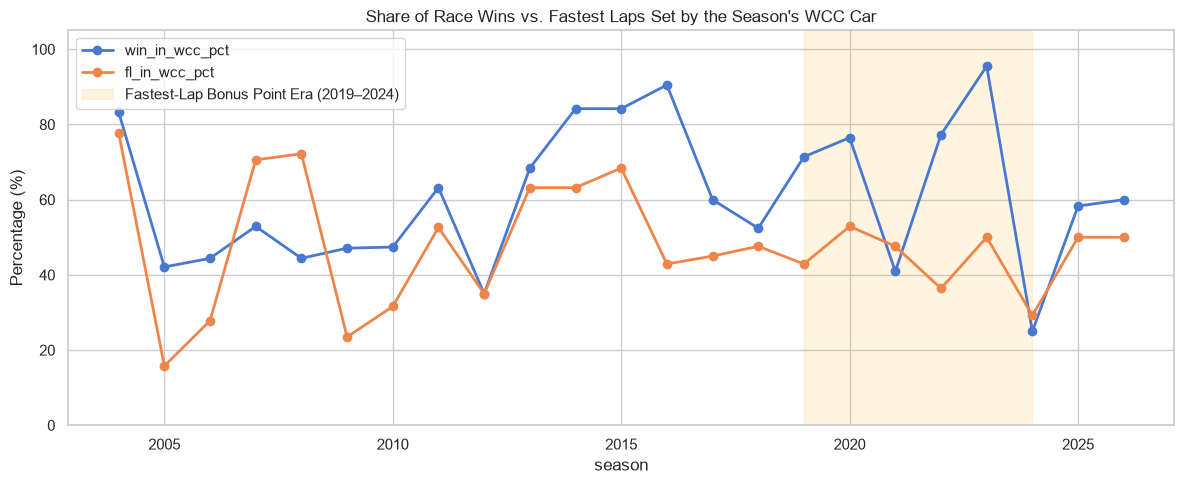

In [7]:
ax = car_dep.plot(marker="o", linewidth=2)
ax.axvspan(2019, 2024, color="orange", alpha=0.12, label="Fastest-Lap Bonus Point Era (2019–2024)")
ax.set_title("Share of Race Wins vs. Fastest Laps Set by the Season's WCC Car")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 105)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Driver-Level Car Dependency: Wins Inside vs. Outside the WCC Car

A quick preview before we add FastF1 rain telemetry: which drivers win the most *without* the Constructors' Championship car?

In [8]:
wcc_era = df[df["season"] >= 1958]

driver_wcc_split = (
    wcc_era[wcc_era["is_win"]]
    .groupby("full_name")
    .agg(
        total_wins=("is_win", "sum"),
        wins_in_wcc_car=("in_wcc_car", "sum"),
    )
    .assign(
        wins_non_wcc_car=lambda d: d["total_wins"] - d["wins_in_wcc_car"],
        non_wcc_win_share_pct=lambda d: (d["wins_non_wcc_car"] / d["total_wins"] * 100).round(1),
    )
    .query("total_wins >= 15")
    .sort_values("wins_non_wcc_car", ascending=False)
)

driver_wcc_split.head(15)

,total_wins,wins_in_wcc_car,wins_non_wcc_car,non_wcc_win_share_pct
full_name,,,,
Max Verstappen,74,34,40,54.1
Michael Schumacher,91,59,32,35.2
Lewis Hamilton,106,81,25,23.6
Alain Prost,51,30,21,41.2
Sebastian Vettel,53,34,19,35.8
Fernando Alonso,32,14,18,56.2
Nelson Piquet,23,7,16,69.6
Jackie Stewart,27,12,15,55.6
Ayrton Senna,41,27,14,34.1


In [9]:
# Filter to Constructors' Championship era (1958–present)
wcc_era = df[df["season"] >= 1958].copy()

# Aggregate year-wise race totals and WCC car wins
yearly_wcc = (
    wcc_era.groupby(["season", "wcc_constructor_name"], as_index=False)
    .agg(
        total_races=("race_id", "nunique"),
        wcc_wins=("is_win", lambda s: (s & wcc_era.loc[s.index, "in_wcc_car"]).sum()),
    )
    .assign(
        non_wcc_wins=lambda d: d["total_races"] - d["wcc_wins"],
        wcc_win_pct=lambda d: (d["wcc_wins"] / d["total_races"] * 100).round(1),
        rolling_5yr_pct=lambda d: (d["wcc_wins"] / d["total_races"] * 100).rolling(5).mean().round(1),
    )
    .sort_values("season")
)

print(f"Historical average (1958–{yearly_wcc['season'].max()}): {yearly_wcc['wcc_win_pct'].mean():.1f}% of races won by the WCC car")
print("\nMost dominant WCC seasons:")
display(yearly_wcc.nlargest(10, "wcc_win_pct")[["season", "wcc_constructor_name", "wcc_wins", "total_races", "wcc_win_pct"]])

print("\nLeast dominant WCC seasons (most competitive):")
display(yearly_wcc.nsmallest(10, "wcc_win_pct")[["season", "wcc_constructor_name", "wcc_wins", "total_races", "wcc_win_pct"]])

# Full year-wise table
yearly_wcc

Historical average (1958–2026): 53.9% of races won by the WCC car

Most dominant WCC seasons:


,season,wcc_constructor_name,wcc_wins,total_races,wcc_win_pct
65,2023,Red Bull,21,22,95.5
30,1988,McLaren,15,16,93.8
58,2016,Mercedes,19,21,90.5
44,2002,Ferrari,15,17,88.2
56,2014,Mercedes,16,19,84.2
57,2015,Mercedes,16,19,84.2
46,2004,Ferrari,15,18,83.3
64,2022,Red Bull,17,22,77.3
62,2020,Mercedes,13,17,76.5
26,1984,McLaren,12,16,75.0



Least dominant WCC seasons (most competitive):


,season,wcc_constructor_name,wcc_wins,total_races,wcc_win_pct
24,1982,Ferrari,3,16,18.8
19,1977,Ferrari,4,17,23.5
66,2024,McLaren,6,24,25.0
16,1974,McLaren,4,15,26.7
23,1981,Williams,4,15,26.7
25,1983,Ferrari,4,15,26.7
6,1964,Ferrari,3,10,30.0
54,2012,Red Bull,7,20,35.0
9,1967,Brabham-Repco,4,11,36.4
18,1976,Ferrari,6,16,37.5


,season,wcc_constructor_name,total_races,wcc_wins,non_wcc_wins,wcc_win_pct,rolling_5yr_pct
0,1958,Vanwall,11,6,5,54.5,NaN
1,1959,Cooper-Climax,9,5,4,55.6,NaN
2,1960,Cooper-Climax,10,6,4,60.0,NaN
3,1961,Ferrari,8,5,3,62.5,NaN
4,1962,BRM,9,4,5,44.4,55.4
...,...,...,...,...,...,...,...
64,2022,Red Bull,22,17,5,77.3,63.7
65,2023,Red Bull,22,21,1,95.5,72.3
66,2024,McLaren,24,6,18,25.0,63.0
67,2025,McLaren,24,14,10,58.3,59.4


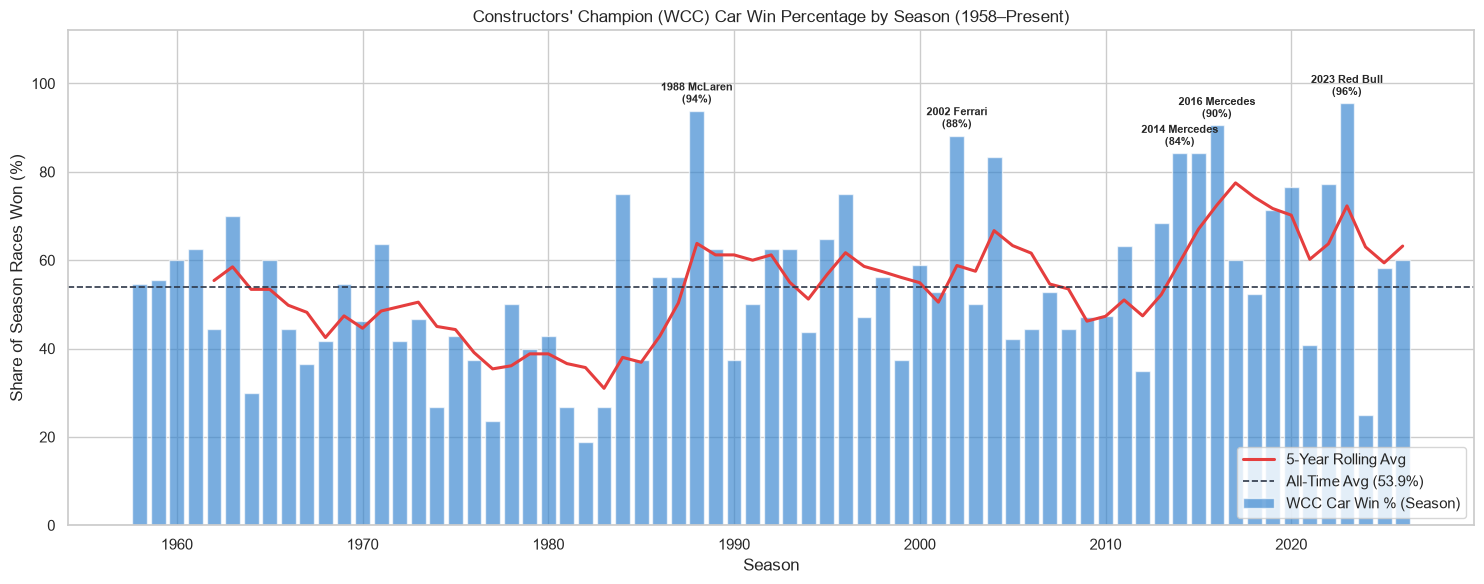

In [10]:
fig, ax = plt.subplots(figsize=(15, 6))

# Year-by-year bars
ax.bar(
    yearly_wcc["season"],
    yearly_wcc["wcc_win_pct"],
    color="#3182ce",
    alpha=0.65,
    label="WCC Car Win % (Season)",
)

# 5-year rolling trendline
ax.plot(
    yearly_wcc["season"],
    yearly_wcc["rolling_5yr_pct"],
    color="#e53e3e",
    linewidth=2.2,
    label="5-Year Rolling Avg",
)

# Historical mean reference line
mean_pct = yearly_wcc["wcc_win_pct"].mean()
ax.axhline(mean_pct, color="#2d3748", linestyle="--", linewidth=1.2, label=f"All-Time Avg ({mean_pct:.1f}%)")

# Annotate top 5 most dominant seasons
for _, row in yearly_wcc.nlargest(5, "wcc_win_pct").iterrows():
    ax.annotate(
        f"{int(row['season'])} {row['wcc_constructor_name']}\n({row['wcc_win_pct']:.0f}%)",
        xy=(row["season"], row["wcc_win_pct"]),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        fontweight="bold",
    )

ax.set_title("Constructors' Champion (WCC) Car Win Percentage by Season (1958–Present)")
ax.set_xlabel("Season")
ax.set_ylabel("Share of Season Races Won (%)")
ax.set_ylim(0, 112)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [11]:
import numpy as np

# Use WCC era (1958–present) and exclude 1950s Indy 500 rounds
data = df[(df["season"] >= 1958) & ~((df["season"] <= 1960) & (df["circuit_id"] == "indianapolis"))].copy()

# 1. Race-level teammate comparison (self-join on race_id + constructor_id)
tm = data[["race_id", "constructor_id", "driver_id", "position", "points"]].merge(
    data[["race_id", "constructor_id", "driver_id", "position", "points"]],
    on=["race_id", "constructor_id"],
    suffixes=("", "_tm"),
)
# Remove self-matches
tm = tm[tm["driver_id"] != tm["driver_id_tm"]].copy()

# Aggregate per driver-race (handles rare 3-car teams cleanly)
race_vs_tm = (
    tm.groupby(["race_id", "driver_id"], as_index=False)
    .agg(
        tm_avg_pos=("position_tm", "mean"),
        beat_tm=("position", lambda s: (s < tm.loc[s.index, "position_tm"]).mean()),
    )
)

# Merge teammate metrics back to race rows
enriched = data.merge(race_vs_tm, on=["race_id", "driver_id"], how="left")
enriched["pos_delta_vs_tm"] = enriched["tm_avg_pos"] - enriched["position"]  # Positive = finished ahead of teammate

# 2. Constructor total points per season
team_season_pts = (
    data.groupby(["season", "constructor_id"], as_index=False)["points"]
    .sum()
    .rename(columns={"points": "team_total_pts"})
)

# 3. Driver-season aggregation
season_races = data.groupby("season")["race_id"].nunique().rename("season_total_races")

driver_season = (
    enriched.groupby(["season", "driver_id", "full_name", "constructor_id", "constructor_name", "in_wcc_car"], as_index=False)
    .agg(
        starts=("race_id", "count"),
        wins=("is_win", "sum"),
        podiums=("is_podium", "sum"),
        driver_pts=("points", "sum"),
        tm_beat_rate=("beat_tm", "mean"),
        avg_pos_delta_vs_tm=("pos_delta_vs_tm", "mean"),
    )
    .merge(team_season_pts, on=["season", "constructor_id"], how="left")
    .merge(season_races, on="season", how="left")
)

# Filter to full-time/meaningful campaigns (>= 60% of season races & >= 3 wins)
driver_season = driver_season[
    (driver_season["starts"] >= driver_season["season_total_races"] * 0.6)
    & (driver_season["wins"] >= 3)
].copy()

driver_season["win_pct"] = (driver_season["wins"] / driver_season["starts"] * 100).round(1)
driver_season["team_pts_share"] = np.where(
    driver_season["team_total_pts"] > 0,
    (driver_season["driver_pts"] / driver_season["team_total_pts"] * 100).round(1),
    0.0,
)
driver_season["tm_beat_pct"] = (driver_season["tm_beat_rate"] * 100).round(1)
driver_season["avg_pos_delta_vs_tm"] = driver_season["avg_pos_delta_vs_tm"].round(2)

# 4. Composite Car-Adjusted Dominance Score (Z-score blend)
def zscore(s):
    return (s - s.mean()) / s.std(ddof=0)

driver_season["dominance_score"] = (
    0.40 * zscore(driver_season["win_pct"])
    + 0.30 * zscore(driver_season["team_pts_share"])
    + 0.20 * zscore(driver_season["avg_pos_delta_vs_tm"].fillna(0))
    + 0.10 * (~driver_season["in_wcc_car"]).astype(float) * 1.5  # Bonus for non-WCC car
).round(2)

cols = [
    "season", "full_name", "constructor_name", "in_wcc_car",
    "wins", "starts", "win_pct", "team_pts_share", "tm_beat_pct", "avg_pos_delta_vs_tm", "dominance_score"
]

print("=== TOP 15 CAR-ADJUSTED DOMINANT SEASONS (ALL CARS) ===")
display(driver_season.sort_values("dominance_score", ascending=False)[cols].head(15))

print("\n=== TOP 15 MOST DOMINANT SEASONS IN A NON-WCC CAR ===")
display(
    driver_season[~driver_season["in_wcc_car"]]
    .sort_values("dominance_score", ascending=False)[cols]
    .head(15)
)

=== TOP 15 CAR-ADJUSTED DOMINANT SEASONS (ALL CARS) ===


,season,full_name,constructor_name,in_wcc_car,wins,starts,win_pct,team_pts_share,tm_beat_pct,avg_pos_delta_vs_tm,dominance_score
339,1963,Jim Clark,Lotus-Climax,True,7,10,70.0,98.6,95.0,12.25,2.50
1750,1994,Michael Schumacher,Benetton,False,8,14,57.1,89.3,85.7,9.36,1.91
2475,2023,Max Verstappen,Red Bull,True,19,22,86.4,67.1,90.9,4.59,1.70
777,1972,Emerson Fittipaldi,Team Lotus,True,5,12,41.7,100.0,90.9,10.00,1.63
450,1965,Jim Clark,Lotus-Climax,True,6,9,66.7,84.4,83.3,3.43,1.49
2526,2025,Max Verstappen,Red Bull,False,8,24,33.3,94.9,95.8,8.88,1.37
279,1962,Graham Hill,BRM,True,4,9,44.4,83.9,94.4,10.17,1.35
2256,2013,Sebastian Vettel,Red Bull,True,13,19,68.4,66.6,94.7,4.37,1.20
538,1967,Jim Clark,Lotus-Ford,False,4,9,44.4,82.0,83.3,6.00,1.17
1961,2002,Michael Schumacher,Ferrari,True,11,17,64.7,65.2,76.5,5.47,1.15



=== TOP 15 MOST DOMINANT SEASONS IN A NON-WCC CAR ===


,season,full_name,constructor_name,in_wcc_car,wins,starts,win_pct,team_pts_share,tm_beat_pct,avg_pos_delta_vs_tm,dominance_score
1750,1994,Michael Schumacher,Benetton,False,8,14,57.1,89.3,85.7,9.36,1.91
2526,2025,Max Verstappen,Red Bull,False,8,24,33.3,94.9,95.8,8.88,1.37
538,1967,Jim Clark,Lotus-Ford,False,4,9,44.4,82.0,83.3,6.00,1.17
1210,1980,Nelson Piquet,Brabham,False,3,14,21.4,98.2,84.6,8.54,1.10
1705,1993,Ayrton Senna,McLaren,False,5,16,31.2,86.9,81.2,7.44,1.03
2500,2024,Max Verstappen,Red Bull,False,9,24,37.5,74.3,95.8,6.00,0.82
806,1972,Jackie Stewart,Tyrrell,False,4,11,36.4,75.0,72.7,5.32,0.76
2430,2021,Max Verstappen,Red Bull,False,10,22,45.5,67.2,86.4,3.41,0.69
1004,1976,James Hunt,McLaren,False,6,16,37.5,78.4,75.0,2.62,0.68
267,1962,Jim Clark,Lotus-Climax,False,3,9,33.3,71.4,71.9,6.13,0.65


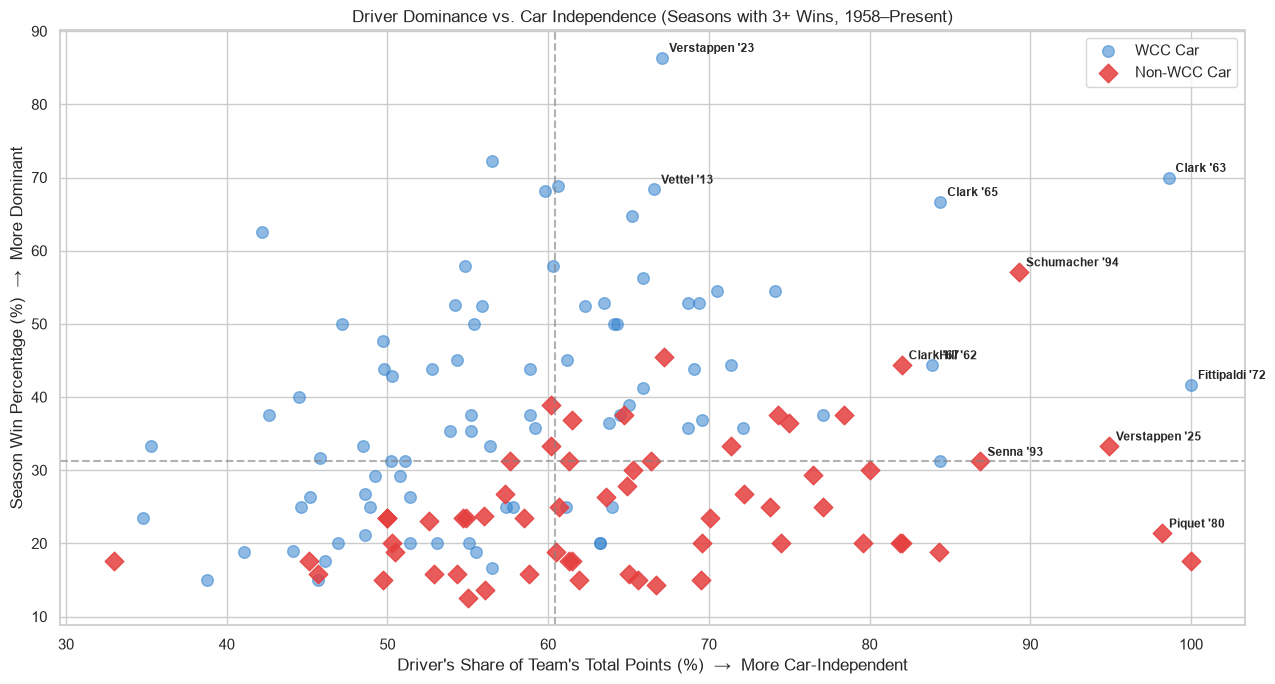

In [12]:
fig, ax = plt.subplots(figsize=(13, 7))

wcc = driver_season[driver_season["in_wcc_car"]]
non_wcc = driver_season[~driver_season["in_wcc_car"]]

ax.scatter(
    wcc["team_pts_share"], wcc["win_pct"],
    alpha=0.55, s=70, color="#3182ce", label="WCC Car"
)
ax.scatter(
    non_wcc["team_pts_share"], non_wcc["win_pct"],
    alpha=0.85, s=90, color="#e53e3e", marker="D", label="Non-WCC Car"
)

# Reference medians to form quadrants
ax.axvline(driver_season["team_pts_share"].median(), color="gray", linestyle="--", alpha=0.6)
ax.axhline(driver_season["win_pct"].median(), color="gray", linestyle="--", alpha=0.6)

# Annotate top 10 overall + top 5 non-WCC outliers
to_label = pd.concat([
    driver_season.nlargest(8, "dominance_score"),
    non_wcc.nlargest(5, "dominance_score"),
]).drop_duplicates(subset=["season", "driver_id"])

for _, row in to_label.iterrows():
    ax.annotate(
        f"{row['full_name'].split()[-1]} '{str(int(row['season']))[2:]}",
        xy=(row["team_pts_share"], row["win_pct"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold",
    )

ax.set_title("Driver Dominance vs. Car Independence (Seasons with 3+ Wins, 1958–Present)")
ax.set_xlabel("Driver's Share of Team's Total Points (%)  →  More Car-Independent")
ax.set_ylabel("Season Win Percentage (%)  →  More Dominant")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
weather = pd.read_csv("data/store/weather.csv")
modern = df[df["season"] >= 2018].merge(
    weather[["race_id", "is_wet_race", "rain_pct", "wet_tire_lap_pct"]],
    on="race_id",
    how="inner",
)

# Filter to classified finishers for clean teammate & position-gain comparisons
classified = modern[modern["status"].str.contains(r"^Finished|^\+\d+ Lap", na=False)].copy()
classified["pos_gained"] = classified["grid"] - classified["position"]

# Teammate delta per race (classified finishers only)
tm = classified[["race_id", "constructor_id", "driver_id", "position"]].merge(
    classified[["race_id", "constructor_id", "driver_id", "position"]],
    on=["race_id", "constructor_id"],
    suffixes=("", "_tm"),
)
tm = tm[tm["driver_id"] != tm["driver_id_tm"]]
tm_delta = (
    tm.groupby(["race_id", "driver_id"], as_index=False)["position_tm"]
    .mean()
    .rename(columns={"position_tm": "tm_pos"})
)
classified = classified.merge(tm_delta, on=["race_id", "driver_id"], how="left")
classified["pos_delta_vs_tm"] = classified["tm_pos"] - classified["position"]

# Aggregate Wet vs. Dry per driver (min 10 wet starts)
wet_dry = (
    modern.groupby(["full_name", "is_wet_race"])
    .agg(starts=("race_id", "count"), wins=("is_win", "sum"), podiums=("is_podium", "sum"))
    .assign(win_pct=lambda d: d["wins"] / d["starts"] * 100)
    .unstack("is_wet_race")
)

# Flatten columns
wet_dry.columns = [f"{col}_{'wet' if is_wet else 'dry'}" for col, is_wet in wet_dry.columns]
wet_dry = wet_dry.reset_index()

# Add classified-only averages (positions gained & teammate delta)
cls_agg = (
    classified.groupby(["full_name", "is_wet_race"])[["pos_gained", "pos_delta_vs_tm"]]
    .mean()
    .unstack("is_wet_race")
)
cls_agg.columns = [f"{col}_{'wet' if is_wet else 'dry'}" for col, is_wet in cls_agg.columns]
wet_dry = wet_dry.merge(cls_agg.reset_index(), on="full_name", how="left")

# Filter to drivers with >= 10 wet races & compute Wet-vs-Dry uplift
wet_leaders = (
    wet_dry[wet_dry["starts_wet"] >= 10]
    .assign(
        win_pct_uplift=lambda d: (d["win_pct_wet"] - d["win_pct_dry"]).round(1),
        tm_delta_uplift=lambda d: (d["pos_delta_vs_tm_wet"] - d["pos_delta_vs_tm_dry"]).round(2),
    )
    .round(2)
    .sort_values("win_pct_wet", ascending=False)
)

cols = [
    "full_name", "starts_wet", "wins_wet", "win_pct_wet", "win_pct_dry",
    "win_pct_uplift", "pos_gained_wet", "pos_delta_vs_tm_wet", "tm_delta_uplift"
]
wet_leaders[cols].head(12)

In [ ]:
top_drivers = wet_leaders.head(10).sort_values("win_pct_wet")

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# Left: Wet vs. Dry Win %
y = range(len(top_drivers))
axes[0].barh([i + 0.18 for i in y], top_drivers["win_pct_wet"], height=0.35, color="#2b6cb0", label="Wet Races")
axes[0].barh([i - 0.18 for i in y], top_drivers["win_pct_dry"], height=0.35, color="#cbd5e0", label="Dry Races")
axes[0].set_yticks(list(y))
axes[0].set_yticklabels(top_drivers["full_name"])
axes[0].set_title("Win %: Wet vs. Dry Races (2018–Present)")
axes[0].set_xlabel("Win Percentage (%)")
axes[0].legend()

# Right: Avg Positions Ahead of Teammate in Wet vs. Dry
axes[1].barh([i + 0.18 for i in y], top_drivers["pos_delta_vs_tm_wet"], height=0.35, color="#2b6cb0", label="Wet Races")
axes[1].barh([i - 0.18 for i in y], top_drivers["pos_delta_vs_tm_dry"], height=0.35, color="#cbd5e0", label="Dry Races")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Avg Positions Ahead of Teammate (Car-Controlled)")
axes[1].set_xlabel("Positions Ahead of Teammate (+ = Better)")
axes[1].legend()

plt.tight_layout()
plt.show()